# 02 · Préparer les données et construire un protocole d'évaluation

**Étapes 3–4** du cas pratique · Slides 18–19, 22–23, 26–28, 34–37.

**Règle de ce notebook.** Le jeu de test est mis sous scellé au début de l'étape 4. D'ici là, **aucune transformation n'est ajustée sur les données réelles** : on n'applique aux vraies lignes que des transformations **sans apprentissage** (`AddFeatures`), et on illustre les transformations qui apprennent sur des **données synthétiques**.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
from sklearn import set_config
from sklearn.linear_model import LogisticRegression

from financial_inclusion_africa import config, features
from financial_inclusion_africa.data import CAT_COLS, DROPPED_COLS, NUM_COLS, clean, load_raw
from financial_inclusion_africa.features import AddFeatures, feature_columns, onehot_preprocessor, pipe

set_config(display="diagram")
pd.set_option("display.max_columns", 30)

## Étape 3 · Préparer les données et construire les variables

### 3.1 Séparer X et y, retirer les colonnes interdites

`clean()` (dans `data.py`) sépare la cible et retire les colonnes qui ne doivent pas servir de variables explicatives, pour les raisons établies à l'étape 2.

In [2]:
df = load_raw()
X, y = clean(df)

print(f"X : {X.shape[0]:,} lignes × {X.shape[1]} colonnes · y : {y.mean():.2%} de positifs")
display(pd.Series(DROPPED_COLS, name="raison").rename_axis("colonne retirée").to_frame())
pd.DataFrame({"type": ["catégorielle"] * len(CAT_COLS) + ["numérique"] * len(NUM_COLS)},
             index=CAT_COLS + NUM_COLS).T

X : 23,524 lignes × 10 colonnes · y : 14.08% de positifs


,raison
colonne retirée,
uniqueid,"identifiant arbitraire, numérotation par pays,..."
year,"entièrement déterminée par country, valeur fut..."


,country,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type,household_size,age_of_respondent
type,catégorielle,catégorielle,catégorielle,catégorielle,catégorielle,catégorielle,catégorielle,catégorielle,numérique,numérique


In [3]:
assert X.shape == (23_524, 10)
assert {"uniqueid", "year", config.TARGET}.isdisjoint(X.columns)
assert y.sum() == 3_312

### 3.2 Feature engineering

`AddFeatures` (dans `features.py`) ajoute des variables qui portent une **idée métier**. Ce sont des règles fixes, écrites à la main : elles **n'apprennent rien des données**, on peut donc les appliquer à n'importe quelle ligne sans risque de fuite.

| Variable | Définition | Idée métier · constat de l'étape 2 |
|---|---|---|
| `education_rank` | 0 (aucune) → 4 (supérieur) ; **NaN** pour *Other/Dont know/RTA* | L'éducation agit dans un ordre (H1) ; la modalité inconnue n'est ni la plus haute ni la plus basse (Q2.6) |
| `education_unknown` *(ajoutée, Q2.6)* | 1 si *Other/Dont know/RTA* | Garde l'information « ne sait pas » après imputation du rang |
| `is_head` | 1 si chef de ménage | 17,7 % ont un compte, contre 6,0 % des parents du chef |
| `formal_job` | 1 si salarié du privé ou de l'État | Salaire versé sur un compte (H2) |
| `urban_phone` | 1 si en ville **et** avec téléphone | Accès physique et numérique aux services |
| `age_group` | 16-25, 26-35, 36-50, 51-65, 66+ | Relation en U inversé ; âges arrondis |
| **`phone_education`** *(la nôtre)* | `education_rank` si téléphone, sinon 0 | Interaction téléphone × éducation (H3) |
| **`lives_alone`** *(la nôtre)* | 1 si ménage d'une personne | 19,1 % ont un compte, contre 14,1 % |

In [4]:
# Sans apprentissage : on peut l'appliquer directement aux vraies lignes
Xf = AddFeatures().fit_transform(X)
new_cols = [c for c in Xf.columns if c not in X.columns]
# quelques lignes, dont une personne d'éducation inconnue
rows = [0, 1, 2, X.index[X["education_level"].eq("Other/Dont know/RTA")][0]]
Xf.loc[rows, ["education_level", "cellphone_access", "household_size", *new_cols]]

,education_level,cellphone_access,household_size,education_rank,education_unknown,is_head,formal_job,urban_phone,age_group,phone_education,lives_alone
0,Secondary education,Yes,3,2.0,0,0,0,0,16-25,2.0,0
1,No formal education,No,5,0.0,0,1,0,0,66+,0.0,0
2,Vocational/Specialised training,Yes,5,3.0,0,0,0,1,26-35,3.0,0
58,Other/Dont know/RTA,Yes,11,NaN,1,0,0,0,16-25,NaN,0


In [5]:
# Contrôle : valeurs prises par les nouvelles variables (effectifs, aucune cible utilisée)
binaires = ["education_unknown", "is_head", "formal_job", "urban_phone", "lives_alone"]
display(Xf[binaires].agg(["sum", "mean"]).T.set_axis(["nombre de 1", "part"], axis=1).round(3))
display(pd.concat({
    "education_rank": Xf["education_rank"].value_counts(dropna=False).sort_index(),
    "phone_education": Xf["phone_education"].value_counts(dropna=False).sort_index(),
}, axis=1).fillna(0).astype(int).rename_axis("valeur"))
Xf["age_group"].value_counts().sort_index().to_frame("effectif")

,nombre de 1,part
education_unknown,35.0,0.001
is_head,12831.0,0.545
formal_job,1442.0,0.061
urban_phone,6384.0,0.271
lives_alone,3057.0,0.130


,education_rank,phone_education
valeur,,
0.0,4515,8578
1.0,12791,9441
2.0,4223,3608
3.0,803,781
4.0,1157,1081
NaN,35,35


,effectif
age_group,
16-25,5601
26-35,6573
36-50,6055
51-65,3329
66+,1966


### 3.3 Assembler un pipeline

Le pipeline enchaîne trois blocs. Les deux derniers **apprennent** ; ils seront ajustés sur les seules lignes d'entraînement de chaque pli.

1. `AddFeatures` : variables métier, sans apprentissage ;
2. `ColumnTransformer` : one-hot des catégorielles (`min_frequency=20`, `handle_unknown="infrequent_if_exist"`), imputation médiane puis `StandardScaler` des numériques ;
3. le modèle : ici notre **modèle de base**, la régression logistique.

`pipe(model, features=..., encoding=..., scale=...)` règle deux choses :
- `features` : `"none"` (colonnes brutes), `"guide"` (variables du guide), `"all"` (guide + nos variables), comparées à l'étape 5 ;
- `encoding` : `"onehot"` (par défaut, régression logistique), `"ordinal"`, `"native"` ou `"native_str"` pour les modèles à base d'arbres (voir les compléments après Q3.4).

In [6]:
logreg = pipe(LogisticRegression(max_iter=2000))
logreg

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('addfeatures', ...), ('columntransformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,custom,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_thresh

In [7]:
pd.DataFrame(
    {f: [len(feature_columns(f)[0]), len(feature_columns(f)[1])] for f in ["none", "guide", "all"]},
    index=["colonnes catégorielles", "colonnes numériques"],
)

,none,guide,all
colonnes catégorielles,8,9,9
colonnes numériques,2,7,9


> **Piège · CatBoost et scikit-learn** (étape 6). CatBoost traite les catégories nativement : on lui passe les colonnes texte telles quelles, sans one-hot. Avec scikit-learn 1.9, `CatBoostClassifier(cat_features=[...])` avec une **liste** ne peut pas être cloné et `cross_validate` échoue ; il faut un **tuple** : `CatBoostClassifier(cat_features=tuple(CAT_COLS), verbose=0)`. Dans le package, `catboost_cat_features()` renvoie ce tuple.

### Q3.1 · Quelles transformations apprennent quelque chose des données ?

In [8]:
# Données synthétiques au schéma du vrai jeu : on ne touche pas aux vraies lignes
rng = np.random.default_rng(config.RANDOM_STATE)

def make_toy(n, age_mean):
    sample = lambda col: rng.choice(X[col].unique(), n)  # seul le schéma est utilisé
    toy = pd.DataFrame({c: sample(c) for c in CAT_COLS})
    toy["household_size"] = rng.integers(1, 10, n)
    toy["age_of_respondent"] = rng.normal(age_mean, 12, n).clip(16, 100).round().astype(int)
    return toy

cat, num = feature_columns("all")
learned = {}
for name, toy in {"pli A (âge moyen 30)": make_toy(400, 30), "pli B (âge moyen 50)": make_toy(400, 50)}.items():
    pre = onehot_preprocessor(cat, num).fit(AddFeatures().fit_transform(toy))
    scaler = pre.named_transformers_["num"][-1]
    imputer = pre.named_transformers_["num"][0]
    learned[name] = {
        "moyenne apprise de l'âge (StandardScaler)": scaler.mean_[num.index("age_of_respondent")],
        "écart-type appris de l'âge": scaler.scale_[num.index("age_of_respondent")],
        "médiane apprise de education_rank (SimpleImputer)": imputer.statistics_[num.index("education_rank")],
        "modalités apprises (OneHotEncoder)": sum(len(c) for c in pre.named_transformers_["cat"].categories_),
    }
pd.DataFrame(learned).round(2)

,pli A (âge moyen 30),pli B (âge moyen 50)
moyenne apprise de l'âge (StandardScaler),29.76,50.26
écart-type appris de l'âge,10.30,11.57
médiane apprise de education_rank (SimpleImputer),2.00,2.00
modalités apprises (OneHotEncoder),41.00,42.00


**Réponse Q3.1.**

| Transformation | Apprend-elle ? | Ce qu'elle apprend (`fit`) |
|---|---|---|
| `clean()` | non | rien : retire des colonnes fixées à l'avance |
| `AddFeatures` | **non** | rien : règles fixes (rangs, seuils, tranches d'âge écrites à la main) |
| `OneHotEncoder` | **oui** | la **liste des modalités** et celles qui sont **rares** (< 20) |
| `SimpleImputer(median)` | **oui** | la **médiane** de chaque colonne numérique |
| `StandardScaler` | **oui** | la **moyenne** et l'**écart-type** de chaque colonne |
| `LogisticRegression` | **oui** | les coefficients |

Le tableau ci-dessus le montre : ajusté sur deux plis différents, le même préprocesseur apprend des paramètres différents (moyenne de l'âge 30 contre 50).

**Pourquoi dans chaque pli, donc dans le pipeline (slide 23) ?** En validation croisée, le pli de validation joue le rôle de données **futures, jamais vues**. Si l'on ajuste le scaler, l'imputer ou l'encodeur sur toutes les lignes *avant* de découper, les moyennes, médianes et listes de modalités contiennent de l'information sur le pli de validation (et sur le test) : c'est une **fuite**, et le score devient optimiste. Placées dans le pipeline, ces étapes sont ré-ajustées par `cross_validate` sur les seules lignes d'entraînement de chaque pli, puis simplement appliquées (`transform`) au pli de validation, exactement comme en production. `AddFeatures` n'apprenant rien, elle ne crée pas de fuite, mais on la met aussi dans le pipeline pour que le modèle final s'applique d'un seul bloc aux données brutes.

### Q3.2 · `handle_unknown="infrequent_if_exist"` et `min_frequency=20`

In [9]:
# Démonstration sur une colonne synthétique : 8 « Dont know », comme dans le vrai jeu
from sklearn.preprocessing import OneHotEncoder

train = pd.DataFrame({"marital_status": ["Married/Living together"] * 120 + ["Single/Never Married"] * 72
                      + ["Dont know"] * 8})
new = pd.DataFrame({"marital_status": ["Single/Never Married", "Dont know", "Jamais vue"]})

variants = {
    "défaut (handle_unknown='error')": OneHotEncoder(sparse_output=False),
    "handle_unknown='ignore'": OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    "min_frequency=20 + infrequent_if_exist": OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist", sparse_output=False),
}
for name, enc in variants.items():
    enc.fit(train)
    try:
        out = pd.DataFrame(enc.transform(new), index=new["marital_status"],
                           columns=enc.get_feature_names_out()).astype(int)
        print(f"\n{name}"); display(out)
    except ValueError as e:
        print(f"\n{name} → ValueError : {str(e)[:90]}…")


défaut (handle_unknown='error') → ValueError : Found unknown categories ['Jamais vue'] in column 0 during transform…

handle_unknown='ignore'


,marital_status_Dont know,marital_status_Married/Living together,marital_status_Single/Never Married
marital_status,,,
Single/Never Married,0,0,1
Dont know,1,0,0
Jamais vue,0,0,0



min_frequency=20 + infrequent_if_exist


,marital_status_Married/Living together,marital_status_Single/Never Married,marital_status_infrequent_sklearn
marital_status,,,
Single/Never Married,0,1,0
Dont know,0,0,1
Jamais vue,0,0,1


**Réponse Q3.2.**
- **`min_frequency=20`** : à l'ajustement, toute modalité vue **moins de 20 fois** dans les lignes d'entraînement est regroupée dans une seule colonne `infrequent_sklearn` au lieu d'avoir la sienne. On évite ainsi des colonnes presque vides, dont le coefficient serait estimé sur une poignée de personnes (variance élevée).
- **`handle_unknown="infrequent_if_exist"`** : à la prédiction, une modalité **jamais vue** à l'entraînement est envoyée dans la colonne « infrequent » si elle existe (sinon elle est codée par des zéros), **sans erreur**. Par défaut (`"error"`), le pipeline plante ; avec `"ignore"`, la ligne est codée en zéros, ce qui revient à la traiter comme la modalité de référence.

**Lien avec Q2.6, cas par cas sur nos données :**
- *Dont know* (`marital_status`, **8 lignes, toutes au Kenya**) : toujours sous le seuil, donc toujours regroupée. En validation croisée **groupée par pays** (étape 4), quand le Kenya est laissé de côté, cette modalité est **inconnue** à l'entraînement : `infrequent_if_exist` évite le plantage.
- *Other/Dont know/RTA* (`education_level`, **35 lignes**) : proche du seuil. On l'attendait vers 35 × 0,8 × 0,8 ≈ 22 par pli d'entraînement ; la vérification de l'étape 4 montre qu'elle est en fait **regroupée dans tous les plis** (15 à 18 occurrences, car le découpage train/test n'en laisse que 21 dans `X_train`). Dans le **rang ordinal**, elle est traitée à part (NaN → médiane + indicateur `education_unknown`).
- `job_type` : **aucune modalité n'est propre à un seul pays**, donc pas de modalité inconnue en CV groupée par pays. Le problème est ailleurs : les questionnaires diffèrent (pas de *Farming and Fishing* en Tanzanie ni en Ouganda), donc une même modalité ne désigne pas la même population d'un pays à l'autre. Aucun réglage d'encodeur ne corrige ce **décalage de sens** : on le mesurera par la CV groupée (Q4.4) et on le citera dans les limites.

### Q3.3 · `education_level` en one-hot et en rang ordinal

In [10]:
# Ce que chaque encodage donne au modèle
edu = pd.DataFrame({"education_level": [*features.EDU_ORDER, "Other/Dont know/RTA"]})
enc_edu = AddFeatures().fit_transform(make_toy(len(edu), 35).assign(education_level=edu["education_level"].to_numpy()))
onehot = pd.get_dummies(edu["education_level"]).astype(int)
pd.concat({"rang ordinal (1 colonne)": enc_edu[["education_rank", "education_unknown"]],
           "one-hot (6 colonnes)": onehot.set_axis(range(len(edu)))}, axis=1).set_axis(edu["education_level"])

rang ordinal (1 colonne)                    \
                                          education_rank education_unknown   
education_level                                                              
No formal education                                  0.0                 0   
Primary education                                    1.0                 0   
Secondary education                                  2.0                 0   
Vocational/Specialised training                      3.0                 0   
Tertiary education                                   4.0                 0   
Other/Dont know/RTA                                  NaN                 1   

                                one-hot (6 colonnes)                      \
                                 No formal education Other/Dont know/RTA   
education_level                                                            
No formal education                                1                   0   
Primary education                                  0                   0   
Secondary education                                0                   0   
Vocational/Specialised training                    0                   0   
Tertiary education                                 0                   0   
Other/Dont know/RTA                                0                   1   

                                                                       \
                                Primary education Secondary education   
education_level                                                         
No formal education                             0                   0   
Primary education                               1                   0   
Secondary education                             0                   1   
Vocational/Specialised training                 0                   0   
Tertiary education                              0                   0   
Other/Dont know/RTA                             0                   0   

                                                    \
                                Tertiary education   
education_level                                      
No formal education                              0   
Primary education                                0   
Secondary education                              0   
Vocational/Specialised training                  0   
Tertiary education                               1   
Other/Dont know/RTA                              0   

                                                                 
                                Vocational/Specialised training  
education_level                                                  
No formal education                                           0  
Primary education                                             0  
Secondary education                                           0  
Vocational/Specialised training                               1  
Tertiary education                                            0  
Other/Dont know/RTA                                           0

**Réponse Q3.3.**
- **Régression logistique → le rang ordinal aide.** Le modèle est linéaire dans le logit : avec le rang, **un seul coefficient** traduit « chaque niveau en plus multiplie la cote par $e^{\beta}$ ». C'est exactement la forme observée (3,9 % → 8,5 % → 23,3 % → 51–57 %, presque monotone) : peu de paramètres, donc peu de variance. Le one-hot donne un coefficient libre par niveau : plus souple (il capte que la formation professionnelle dépasse légèrement le supérieur), mais il ignore l'ordre. Garder **les deux** permet au modèle d'avoir la tendance (rang) et les écarts à la tendance (one-hot), la régularisation L2 évitant la redondance.
- **Arbre → le rang ordinal aide aussi, d'une autre façon.** Un arbre coupe sur un seuil : avec le rang, une seule coupure `education_rank ≥ 3` sépare « professionnel ou supérieur » du reste. Avec le one-hot, il faut plusieurs coupures successives (une par colonne), ce qui demande plus de profondeur. Pour un arbre, le rang est donc l'encodage le plus efficace ; le one-hot reste utile pour isoler une modalité particulière.
- **Q2.6** : *Other/Dont know/RTA* n'a pas de place dans l'ordre. Le guide la code −1 (sous « aucune éducation »), ce qui invente un ordre ; nous la codons **NaN**, imputée par la médiane apprise dans le pli, avec l'indicateur `education_unknown`. Le one-hot la garde comme modalité à part entière (31 % de ces personnes ont un compte).

### Q3.4 · Le `StandardScaler` : utile pour une forêt ? pour une régression logistique ?

In [11]:
# Expérience sur données synthétiques : deux variables d'échelles très différentes
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

Xs, ys = make_classification(n_samples=2000, n_features=5, n_informative=3, random_state=config.RANDOM_STATE)
Xs = Xs * np.array([1, 10, 100, 1000, 10000])  # échelles de 1 à 10 000
Xs_scaled = StandardScaler().fit_transform(Xs)

rf_raw = RandomForestClassifier(n_estimators=100, random_state=config.RANDOM_STATE).fit(Xs, ys)
rf_std = RandomForestClassifier(n_estimators=100, random_state=config.RANDOM_STATE).fit(Xs_scaled, ys)
lr_raw = LogisticRegression(max_iter=5000).fit(Xs, ys)
lr_std = LogisticRegression(max_iter=5000).fit(Xs_scaled, ys)

pd.DataFrame({
    "forêt aléatoire": {"prédictions identiques brut / standardisé": np.allclose(rf_raw.predict_proba(Xs), rf_std.predict_proba(Xs_scaled)),
                        "itérations de l'optimiseur": "—"},
    "régression logistique": {"prédictions identiques brut / standardisé": np.allclose(lr_raw.predict_proba(Xs), lr_std.predict_proba(Xs_scaled)),
                              "itérations de l'optimiseur": f"{lr_raw.n_iter_[0]} (brut) contre {lr_std.n_iter_[0]} (standardisé)"},
})

,forêt aléatoire,régression logistique
prédictions identiques brut / standardisé,True,False
itérations de l'optimiseur,—,49 (brut) contre 9 (standardisé)


**Réponse Q3.4.**
- **Forêt aléatoire : inutile (mais sans danger).** Un arbre coupe sur des seuils `x ≤ s` ; une transformation croissante de `x` (comme la standardisation) déplace le seuil mais ne change aucune partition. Les prédictions sont **identiques** avec ou sans standardisation (expérience ci-dessus).
- **Régression logistique : utile, pour deux raisons.**
  1. **La régularisation** : par défaut, `LogisticRegression` pénalise $\lambda\sum_j \beta_j^2$ (L2, `C=1`). La taille d'un coefficient dépend de l'unité de sa variable : l'âge (16 à 100) a un petit coefficient, une indicatrice 0/1 un grand. Sans standardisation, la pénalité frappe les variables **inégalement**, pour une raison d'unité et non d'importance ; les prédictions changent (expérience ci-dessus).
  2. **L'optimisation** : l'optimiseur (L-BFGS) converge bien plus vite quand les variables sont à la même échelle.

  La standardisation rend aussi les coefficients **comparables** entre eux, ce qui aide l'interprétation. Ici, les variables numériques (âge, taille du ménage, rang d'éducation) et les indicatrices one-hot (0/1) ont des échelles différentes : on standardise les numériques, dans le pipeline.

### Compléments · encoder selon la famille de modèle

Q3.4 l'a montré pour la standardisation : les modèles à base d'arbres n'ont pas besoin des mêmes préparations que la régression logistique. Il en va de même pour les catégories. Plusieurs de ces modèles savent les traiter **nativement**, sans one-hot :

| Modèle | Standardisation | Catégories natives ? | Comment |
|---|---|---|---|
| Régression logistique | **indispensable** | non | one-hot |
| Random Forest (scikit-learn 1.9) | inutile | **non** : une colonne texte fait planter `fit` | one-hot ou codes entiers (ordinal) |
| HistGradientBoosting | inutile | oui | dtype `category` (`categorical_features="from_dtype"`) |
| XGBoost | inutile | oui | dtype `category` + `enable_categorical=True` |
| LightGBM | inutile | oui | dtype `category` ; cherche le meilleur regroupement de modalités à chaque coupure |
| CatBoost | inutile | oui, le plus abouti | `cat_features` (tuple) ; statistiques de cible ordonnées, sans fuite (slide 35) |

D'où l'option `encoding` de `pipe()` :

| `encoding` | Catégorielles | Numériques | Pour |
|---|---|---|---|
| `"onehot"` | one-hot | imputation + standardisation (`scale=False` pour l'omettre) | régression logistique ; comparaison du guide à l'étape 6 |
| `"ordinal"` | codes entiers | intactes, NaN compris | forêt aléatoire |
| `"native"` | dtype `category` | intactes, NaN compris | XGBoost, LightGBM, HistGB |
| `"native_str"` | texte | intactes, NaN compris | CatBoost |

**Q2.6, partout le même traitement.** Chaque encodage **apprend** dans le pli les modalités fréquentes (≥ 20) ; les modalités rares et celles jamais vues sont regroupées (`infrequent`) ou codées −1. Sans cela, chaque bibliothèque appliquerait sa propre règle (LightGBM envoie une modalité inconnue vers la branche « manquant », CatBoost lisse les modalités rares par un a priori…), et les comparaisons de l'étape 6 mélangeraient deux effets : le modèle et la gestion des modalités.

In [12]:
# Les trois préparations sur des données synthétiques, avec une modalité jamais vue
from financial_inclusion_africa.features import NativeCategories, ordinal_preprocessor

toy = make_toy(400, 35)
frequent = ["Married/Living together", "Single/Never Married", "Widowed", "Divorced/Seperated"]
toy["marital_status"] = rng.choice(frequent, len(toy))
toy.loc[:7, "marital_status"] = "Dont know"  # 8 occurrences : rare, comme dans le vrai jeu
new = make_toy(3, 35).assign(marital_status=["Dont know", "Jamais vue", "Married/Living together"])
toy_f, new_f = AddFeatures().fit_transform(toy), AddFeatures().fit_transform(new)

onehot_pre = onehot_preprocessor(cat, num, scale=False).fit(toy_f)
oh = pd.DataFrame(onehot_pre.transform(new_f), columns=onehot_pre.get_feature_names_out())
ordinal_pre = ordinal_preprocessor(cat, num).fit(toy_f)
native_pre = NativeCategories(cat, num).fit(toy_f)

pd.DataFrame({
    "marital_status (brut)": new["marital_status"].to_numpy(),
    "one-hot : colonne activée": [", ".join(c.removeprefix("cat__marital_status_") for c in oh.columns[(oh.loc[i] == 1)] if "marital" in c) or "aucune" for i in range(3)],
    "ordinal : code": ordinal_pre.transform(new_f)["marital_status"].to_numpy(),
    "native : catégorie": native_pre.transform(new_f)["marital_status"].astype(str).to_numpy(),
})

,marital_status (brut),one-hot : colonne activée,ordinal : code,native : catégorie
0,Dont know,infrequent_sklearn,4.0,infrequent
1,Jamais vue,infrequent_sklearn,-1.0,infrequent
2,Married/Living together,Married/Living together,1.0,Married/Living together


In [13]:
# Nombre de colonnes envoyées au modèle selon l'encodage (variables "all")
pd.Series({
    "onehot": oh.shape[1],
    "ordinal": ordinal_pre.transform(new_f).shape[1],
    "native / native_str": native_pre.transform(new_f).shape[1],
}, name="colonnes").to_frame()

,colonnes
onehot,51
ordinal,18
native / native_str,18


**Ce qu'on retient.**
- Le one-hot multiplie les colonnes (une par modalité) ; l'ordinal et le natif gardent une colonne par variable, ce qui accélère les arbres et leur permet de regrouper des modalités en une seule coupure.
- *Dont know* (rare) et *Jamais vue* (inconnue) sont traitées sans erreur dans les trois encodages. En one-hot et en natif, les deux tombent dans la même modalité « infrequent ». En ordinal, la rare reçoit le code partagé des modalités rares (4) et l'inconnue le code −1 : `OrdinalEncoder` n'a pas d'option `infrequent_if_exist`. Pour un arbre, ce sont deux valeurs « à part », ce qui reste acceptable.
- **Étape 6** : on fera la comparaison du guide (forêt, XGBoost, LightGBM en one-hot, CatBoost en natif, Q6.4), puis on la complétera avec l'encodage natif pour XGBoost et LightGBM, pour séparer l'effet de l'encodage de celui de l'algorithme.

### Q3.5 · Variables supplémentaires justifiées par le métier

**Réponse Q3.5.** Nous ajoutons deux variables, en plus de celles du guide :

1. **`phone_education`** = rang d'éducation si la personne a un téléphone, 0 sinon.
   - *Idée métier* : KaziPay vend un **service de paiement mobile** ; il faut à la fois le canal (le téléphone) et la capacité à utiliser des services financiers (l'éducation).
   - *Constat* (étape 2) : sans téléphone, la part des personnes qui ont un compte reste sous 7 % quel que soit le niveau d'éducation ; avec téléphone, elle monte de 5 % à 54 %. Les deux effets **se multiplient** : une régression logistique additive ne peut pas le représenter sans ce terme croisé (un arbre, si).
2. **`lives_alone`** = 1 si le ménage compte une seule personne.
   - *Idée métier* : une personne seule gère elle-même ses revenus et ses paiements.
   - *Constat* : 19,1 % des personnes seules ont un compte, contre 14,1 % en moyenne, alors que l'effet de la taille du ménage est faible ailleurs : un **seuil**, pas une pente.

**Mesure à l'étape 5** : `pipe(..., features="guide")` contre `pipe(..., features="all")` pour la régression logistique, sur les mêmes plis. On ne conclura à un gain que si l'écart de PR-AUC dépasse l'écart-type entre plis.

### Synthèse de l'étape 3

- `clean()` retire `uniqueid` et `year` ; `X` garde 8 colonnes catégorielles et 2 numériques.
- `AddFeatures` ajoute les 5 variables du guide, l'indicateur `education_unknown` (Q2.6) et nos 2 variables (Q3.5), sans rien apprendre.
- Le préprocesseur (one-hot, imputation, standardisation) apprend ses paramètres et vit dans le pipeline, ajusté pli par pli.
- Les pièges de Q2.6 sont traités explicitement et testés (`tests/test_features.py`) : modalités rares regroupées, modalité inconnue sans erreur, *Other/Dont know/RTA* manquante dans le rang ordinal.
- Aucun ajustement sur les vraies données à ce stade : le test sera mis sous scellé au début de l'étape 4.

## Étape 4 · Construire un protocole d'évaluation honnête

### 4.1 Mettre le test sous scellé

Le découpage est fait **une seule fois**, par `load_split()` (`data.py`) : stratifié sur la cible, 20 % de test, `random_state=42`. Tous les notebooks suivants appellent cette même fonction et obtiennent exactement le même découpage.

> **À partir d'ici, `X_test` et `y_test` ne servent plus jusqu'à l'étape 10.** Toute décision prise en regardant le test le transformerait en validation (slide 23).

In [14]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import KFold, StratifiedGroupKFold, StratifiedKFold, cross_validate

from financial_inclusion_africa import viz
from financial_inclusion_africa.data import load_split
from financial_inclusion_africa.evaluate import (
    CV, SCORING, T_STAR, evaluate_cv, fold_scores, format_summary, per_group_scores,
)
from financial_inclusion_africa.features import fold_category_audit

viz.set_style()
X_train, X_test, y_train, y_test = load_split()

pd.DataFrame(
    {"lignes": [len(X_train), len(X_test)],
     "personnes qui ont un compte": [y_train.sum(), y_test.sum()],
     "prévalence": [y_train.mean(), y_test.mean()]},
    index=["X_train", "X_test"],
).round(4)

,lignes,personnes qui ont un compte,prévalence
X_train,18819,2650,0.1408
X_test,4705,662,0.1407


In [15]:
# La stratification porte sur la cible ; on vérifie aussi que chaque pays est représenté
pd.concat(
    {"part dans X_train": X_train["country"].value_counts(normalize=True),
     "part dans X_test": X_test["country"].value_counts(normalize=True),
     "prévalence X_train": y_train.groupby(X_train["country"]).mean(),
     "prévalence X_test": y_test.groupby(X_test["country"]).mean()}, axis=1
).round(3)

,part dans X_train,part dans X_test,prévalence X_train,prévalence X_test
country,,,,
Rwanda,0.371,0.371,0.116,0.112
Tanzania,0.284,0.271,0.092,0.092
Kenya,0.258,0.257,0.248,0.260
Uganda,0.087,0.101,0.089,0.076


Le découpage stratifié garde **14,08 %** de positifs dans `X_train` et **14,07 %** dans `X_test`. Les pays ne sont pas stratifiés explicitement : leur part et leur prévalence restent proches dans les deux jeux, avec de petits écarts dus au hasard (Ouganda : 8,7 % des lignes de `X_train` contre 10,1 % du test ; Kenya : 24,8 % de positifs dans `X_train` contre 26,0 % dans le test). Chaque pays est bien représenté des deux côtés.

### 4.2 La validation croisée stratifiée, un seul objet pour tous

L'objet `CV` est défini **une fois** dans `evaluate.py` : `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Les métriques (`SCORING`) sont celles du guide, plus la précision, le recall et le coût par personne au seuil $t^* \approx 0{,}091$ (étape 1). `cv_summary()` transforme le résultat de `cross_validate` en une ligne de tableau : moyenne et écart-type de chaque métrique, en entraînement et en validation, signes « neg_ » remis au positif, et temps d'entraînement.

In [16]:
# Composition des plis : 5 plis de validation de taille et de prévalence identiques
pd.DataFrame(
    [{"lignes": len(va), "positifs": int(y_train.iloc[va].sum()), "prévalence": y_train.iloc[va].mean()}
     for _, va in CV.split(X_train, y_train)]
).rename_axis("pli").round(4)

,lignes,positifs,prévalence
pli,,,
0,3764,530,0.1408
1,3764,530,0.1408
2,3764,530,0.1408
3,3764,530,0.1408
4,3763,530,0.1408


In [17]:
# Le plancher et le modèle de base, évalués avec le même protocole
models = {
    "plancher (DummyClassifier « prior »)": DummyClassifier(strategy="prior"),
    "modèle de base (régression logistique)": pipe(LogisticRegression(max_iter=2000)),
}
rows, results = [], {}
for name, model in models.items():
    row, results[name] = evaluate_cv(model, X_train, y_train, name=name)
    rows.append(row)
summary = pd.DataFrame(rows)
print("Validation (moyenne ± écart-type sur les 5 plis)")
display(format_summary(summary))
print("Entraînement")
format_summary(summary, part="train")

Validation (moyenne ± écart-type sur les 5 plis)


,pr_auc,roc_auc,brier,logloss,acc,precision_t,recall_t,cost_t,temps (s)
plancher (DummyClassifier « prior »),0.141 ± 0.000,0.500 ± 0.000,0.121 ± 0.000,0.406 ± 0.000,0.859 ± 0.000,0.141 ± 0.000,1.000 ± 0.000,0.430 ± 0.000,0.02
modèle de base (régression logistique),0.561 ± 0.026,0.849 ± 0.010,0.087 ± 0.003,0.292 ± 0.009,0.885 ± 0.005,0.279 ± 0.004,0.852 ± 0.011,0.259 ± 0.006,0.24


Entraînement


,pr_auc,roc_auc,brier,logloss,acc,precision_t,recall_t,cost_t,temps (s)
plancher (DummyClassifier « prior »),0.141 ± 0.000,0.500 ± 0.000,0.121 ± 0.000,0.406 ± 0.000,0.859 ± 0.000,0.141 ± 0.000,1.000 ± 0.000,0.430 ± 0.000,0.02
modèle de base (régression logistique),0.566 ± 0.006,0.853 ± 0.002,0.086 ± 0.001,0.289 ± 0.002,0.885 ± 0.001,0.280 ± 0.002,0.857 ± 0.003,0.256 ± 0.002,0.24


In [18]:
# Scores pli par pli du modèle de base
fold_scores(results["modèle de base (régression logistique)"]).round(3)

,pr_auc,roc_auc,brier,logloss,acc,precision_t,recall_t,cost_t
pli,,,,,,,,
0,0.552,0.847,0.088,0.294,0.884,0.285,0.849,0.256
1,0.591,0.855,0.084,0.285,0.888,0.275,0.868,0.254
2,0.576,0.851,0.085,0.288,0.890,0.274,0.853,0.263
3,0.514,0.833,0.092,0.309,0.877,0.278,0.834,0.269
4,0.569,0.861,0.085,0.284,0.887,0.283,0.858,0.253


**Lecture.** La régression logistique obtient une **PR-AUC de 0,561 ± 0,026** en validation, contre 0,141 pour le plancher (la prévalence) : elle apprend nettement quelque chose. Les scores d'entraînement et de validation sont très proches (0,566 contre 0,561) : peu de surapprentissage, ce qu'on analysera à l'étape 5. Au seuil $t^*$, elle trouve environ **85 %** des personnes qui ont un compte (recall), avec une précision d'environ 28 % : c'est le choix voulu par les coûts (un oubli coûte 10 fois plus qu'un contact inutile). Le coût moyen descend à **0,26 USD par personne**, contre 0,43 USD si l'on contacte tout le monde (étape 9).

### Q4.1 · Pourquoi stratifier ?

,KFold,StratifiedKFold
min,0,4
max,11,4
écart-type,1.79,0.0
plis avec 0 positif,1.2%,0.0%
plis avec ≤ 1 positif,6.6%,0.0%


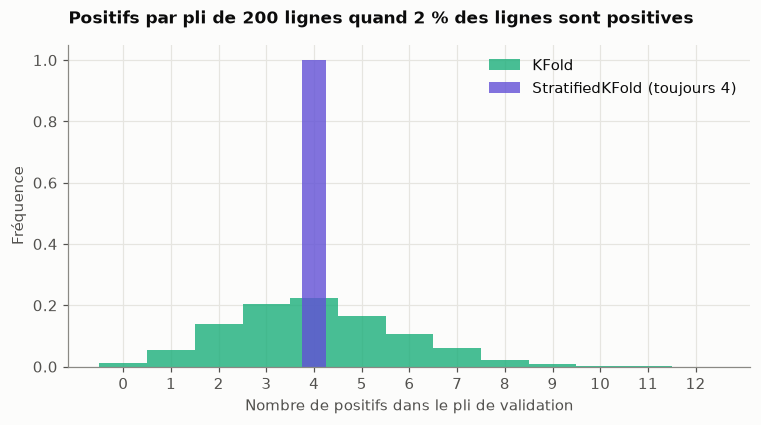

,KFold,StratifiedKFold (CV)
pli,,
0,561,530
1,535,530
2,518,530
3,545,530
4,491,530


In [19]:
# Simulation : 1 000 lignes, 2 % de positifs, 5 plis de 200 lignes, 1 000 découpages
y_sim = np.zeros(1000, dtype=int)
y_sim[:20] = 1
positives = {"KFold": [], "StratifiedKFold": []}
for seed in range(1000):
    for name, splitter in [("KFold", KFold(5, shuffle=True, random_state=seed)),
                           ("StratifiedKFold", StratifiedKFold(5, shuffle=True, random_state=seed))]:
        positives[name] += [y_sim[va].sum() for _, va in splitter.split(np.zeros(1000), y_sim)]
positives = {k: np.array(v) for k, v in positives.items()}

display(pd.DataFrame({k: {"min": v.min(), "max": v.max(), "écart-type": v.std().round(2),
                          "plis avec 0 positif": f"{(v == 0).mean():.1%}",
                          "plis avec ≤ 1 positif": f"{(v <= 1).mean():.1%}"} for k, v in positives.items()}))

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(-0.5, 13.5, 1)
ax.hist(positives["KFold"], bins=bins, color=viz.COMPOSITION[0], alpha=0.8, label="KFold", density=True)
ax.hist(positives["StratifiedKFold"], bins=bins, color=viz.COMPOSITION[1], alpha=0.8,
        label="StratifiedKFold (toujours 4)", density=True, rwidth=0.5)
ax.set(title="Positifs par pli de 200 lignes quand 2 % des lignes sont positives",
       xlabel="Nombre de positifs dans le pli de validation", ylabel="Fréquence")
ax.set_xticks(range(0, 13))
ax.legend()
viz.save(fig, "04_positifs_par_pli")
plt.show()

# Sur nos données : positifs par pli, KFold contre StratifiedKFold
pd.DataFrame({
    "KFold": [y_train.iloc[va].sum() for _, va in KFold(5, shuffle=True, random_state=config.RANDOM_STATE).split(X_train)],
    "StratifiedKFold (CV)": [y_train.iloc[va].sum() for _, va in CV.split(X_train, y_train)],
}).rename_axis("pli")

**Réponse Q4.1.** Stratifier garantit que **chaque partie a la même proportion de positifs** que l'ensemble (14,1 %).

- **Pour le découpage train/test** : le test doit ressembler aux données sur lesquelles le modèle sera utilisé ; sans stratification, il pourrait contenir par hasard plus ou moins de positifs, et la métrique finale serait biaisée dans un sens ou dans l'autre.
- **Pour les plis** : la PR-AUC dépend directement de la prévalence (son niveau de hasard *est* la prévalence, Q4.3). Des plis de prévalences différentes donnent des scores qui varient pour une raison sans rapport avec le modèle : l'écart-type gonfle. Sur nos données, `KFold` donne entre 491 et 561 positifs par pli, `StratifiedKFold` 530 partout.

**Avec 2 % de positifs et des plis de 200 lignes**, on attend 4 positifs par pli. Sans stratification, la simulation donne de **0 à 11** positifs ; **6,6 % des plis** en ont un seul ou aucun. Avec 0 positif, la PR-AUC et la ROC-AUC sont **indéfinies** (scikit-learn renvoie `nan` ou une erreur) ; avec 1 ou 2, elles sont **extrêmement bruitées** (un seul positif bien ou mal classé fait varier la PR-AUC de 0 à 1). La moyenne et l'écart-type deviennent inexploitables. `StratifiedKFold` donne **exactement 4** positifs dans chaque pli.

### Q4.2 · Pourquoi le même objet `cv` pour tous les modèles ?

In [20]:
# Deux modèles proches : régression logistique avec régularisation normale (C=1) et forte (C=0,05)
lr_a = pipe(LogisticRegression(max_iter=2000, C=1.0))
lr_b = pipe(LogisticRegression(max_iter=2000, C=0.05))
same_a = cross_validate(lr_a, X_train, y_train, cv=CV, scoring="average_precision", n_jobs=-1)["test_score"]
same_b = cross_validate(lr_b, X_train, y_train, cv=CV, scoring="average_precision", n_jobs=-1)["test_score"]
other_cv = StratifiedKFold(5, shuffle=True, random_state=7)
other_b = cross_validate(lr_b, X_train, y_train, cv=other_cv, scoring="average_precision", n_jobs=-1)["test_score"]

pd.DataFrame({
    "A (C=1), plis CV": same_a, "B (C=0,05), plis CV": same_b, "B − A, mêmes plis": same_b - same_a,
    "B (C=0,05), autres plis": other_b, "B − A, plis différents": other_b - same_a,
}).rename_axis("pli").pipe(lambda t: pd.concat([t, t.agg(["mean", "std"])])).round(4)

,"A (C=1), plis CV","B (C=0,05), plis CV","B − A, mêmes plis","B (C=0,05), autres plis","B − A, plis différents"
0,0.5524,0.5532,0.0007,0.5813,0.0289
1,0.5908,0.5911,0.0003,0.5532,-0.0376
2,0.5756,0.5748,-0.0008,0.5501,-0.0255
3,0.5144,0.5113,-0.0031,0.5743,0.0599
4,0.5693,0.5688,-0.0005,0.5478,-0.0216
mean,0.5605,0.5598,-0.0007,0.5614,0.0008
std,0.0292,0.0303,0.0015,0.0154,0.0417


**Réponse Q4.2.** Avec le **même objet `cv`**, tous les modèles sont entraînés et évalués sur **exactement les mêmes lignes** dans chaque pli.

- **Comparaison équitable** : un écart de score vient alors des modèles, pas du hasard du découpage. Certains plis sont « faciles » et d'autres « difficiles » pour tous les modèles (ici, la PR-AUC du pli 3 est la plus basse pour les deux variantes).
- **Comparaison appariée** : on peut calculer la différence **pli par pli**. Dans le tableau ci-dessus, l'écart-type de la différence B − A est bien plus faible sur les mêmes plis que sur des plis différents : la difficulté propre à chaque pli s'annule. C'est ce qui permettra de dire si un modèle bat vraiment le modèle de base (Q6.2, slides 24 et 38).
- **Reproductibilité** : `random_state` fixé, défini une seule fois dans `evaluate.py`, donc identique dans tous les notebooks.

### Q4.3 · Pourquoi la PR-AUC plutôt que la ROC-AUC ?

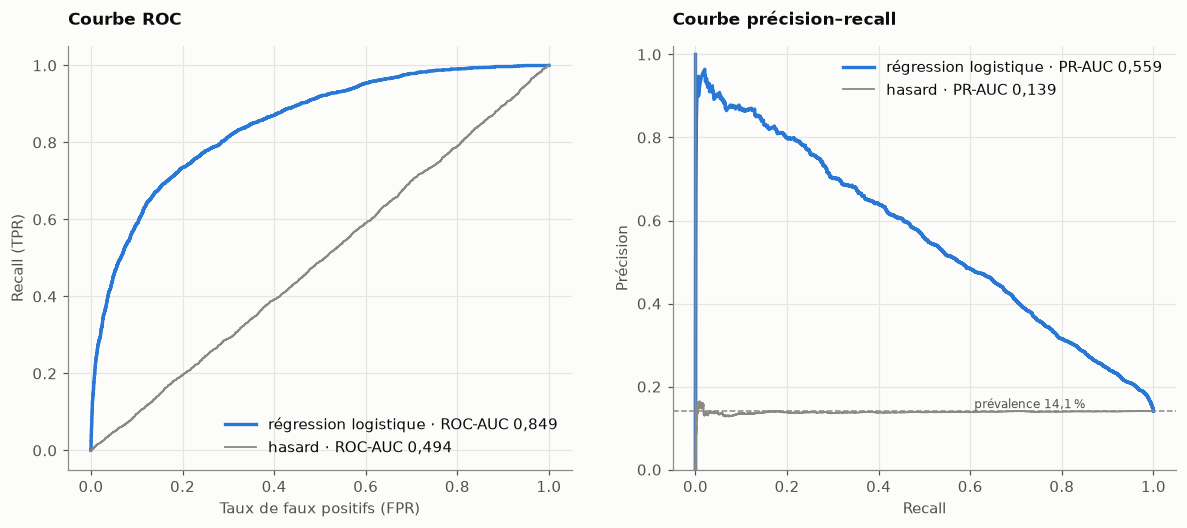

Au seuil t* : 2 259 vrais positifs, 5 843 faux positifs → FPR = 36,1 %, précision = 27,9 %, 2,6 contacts inutiles par client trouvé


In [21]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_predict

# Probabilités « hors pli » du modèle de base (chaque ligne prédite par un modèle qui ne l'a pas vue)
oof = cross_val_predict(pipe(LogisticRegression(max_iter=2000)), X_train, y_train, cv=CV,
                        method="predict_proba", n_jobs=-1)[:, 1]
random_scores = np.random.default_rng(config.RANDOM_STATE).random(len(y_train))
prevalence = y_train.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for scores, label, color, lw in [(oof, "régression logistique", viz.YES, 2.2), (random_scores, "hasard", viz.INK_3, 1.2)]:
    fpr, tpr, _ = roc_curve(y_train, scores)
    prec, rec, _ = precision_recall_curve(y_train, scores)
    ax1.plot(fpr, tpr, color=color, lw=lw, label=f"{label} · ROC-AUC {viz.fr(f'{roc_auc_score(y_train, scores):.3f}')}")
    ax2.plot(rec, prec, color=color, lw=lw, label=f"{label} · PR-AUC {viz.fr(f'{average_precision_score(y_train, scores):.3f}')}")
ax2.axhline(prevalence, color=viz.INK_3, ls="--", lw=1)
ax2.annotate(f" prévalence {viz.fmt_pct(prevalence)}", (0.6, prevalence), va="bottom", fontsize=8, color=viz.INK_2)
ax1.set(title="Courbe ROC", xlabel="Taux de faux positifs (FPR)", ylabel="Recall (TPR)")
ax2.set(title="Courbe précision–recall", xlabel="Recall", ylabel="Précision", ylim=(0, 1.02))
for ax in (ax1, ax2):
    ax.legend(loc="lower right" if ax is ax1 else "upper right")
viz.save(fig, "04_courbes_roc_pr")
plt.show()

# Lecture au seuil t* : combien de faux positifs pour un FPR donné ?
pred = oof >= T_STAR
fp, tp = int((pred & (y_train == 0)).sum()), int((pred & (y_train == 1)).sum())
print(f"Au seuil t* : {viz.fmt_int(tp)} vrais positifs, {viz.fmt_int(fp)} faux positifs → "
      f"FPR = {viz.fmt_pct(fp / (y_train == 0).sum())}, précision = {viz.fmt_pct(tp / (tp + fp))}, "
      f"{viz.fr(f'{fp / tp:.1f}')} contacts inutiles par client trouvé")

**Réponse Q4.3.**
- **La ROC-AUC est flattée par les nombreux négatifs.** Son axe horizontal, le taux de faux positifs $FPR = FP / (FP + TN)$, divise par les **16 169 négatifs** de `X_train`. Au seuil $t^*$, le modèle de base produit 5 843 faux positifs pour 2 259 vrais positifs : un FPR de 36 % seulement, mais pour KaziPay, ce sont **2,6 contacts inutiles pour chaque client trouvé** (précision 27,9 %). La courbe ROC monte vite et donne une impression de modèle excellent (0,849).
- **La PR-AUC regarde la classe qui compte.** La précision $TP / (TP + FP)$ répond directement à la question métier : *parmi les personnes contactées, combien ont un compte ?* Elle est sensible au déséquilibre, ce qui est voulu ici : la PR-AUC du modèle (0,56) montre qu'il reste une marge importante, ce que la ROC-AUC masque.
- **Modèle au hasard** : sa PR-AUC vaut la **prévalence**, ici **≈ 0,141** (0,139 avec des scores aléatoires) ; sa ROC-AUC vaut 0,5 quelle que soit la prévalence. Une PR-AUC se lit donc toujours par rapport à la prévalence : 0,56 représente **4 fois** le hasard.

### 4.3 Expérience : généraliser à un pays jamais vu

`StratifiedGroupKFold` garde chaque groupe entier du même côté du découpage. Avec le pays comme groupe et `n_splits=4`, chaque pli de validation contient exactement un pays, jamais vu à l'entraînement.

In [22]:
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=config.RANDOM_STATE)
groups = X_train["country"]
for i, (tr, va) in enumerate(sgkf.split(X_train, y_train, groups)):
    print(i, list(groups.iloc[va].unique()), y_train.iloc[va].mean().round(3),
          "| pays à l'entraînement :", sorted(groups.iloc[tr].unique()))

0 ['Rwanda'] 0.116 | pays à l'entraînement : ['Kenya', 'Tanzania', 'Uganda']
1 ['Tanzania'] 0.092 | pays à l'entraînement : ['Kenya', 'Rwanda', 'Uganda']
2 ['Uganda'] 0.089 | pays à l'entraînement : ['Kenya', 'Rwanda', 'Tanzania']
3 ['Kenya'] 0.248 | pays à l'entraînement : ['Rwanda', 'Tanzania', 'Uganda']


In [23]:
logreg = pipe(LogisticRegression(max_iter=2000))
row_pays, res_pays = evaluate_cv(logreg, X_train, y_train, cv=sgkf, groups=groups, name="CV groupée par pays")
row_strat = summary.loc["modèle de base (régression logistique)"].rename("CV stratifiée (5 plis)")
format_summary(pd.DataFrame([row_strat, row_pays]), metrics=["pr_auc", "roc_auc", "brier", "logloss", "recall_t", "cost_t"])

,pr_auc,roc_auc,brier,logloss,recall_t,cost_t,temps (s)
CV stratifiée (5 plis),0.561 ± 0.026,0.849 ± 0.010,0.087 ± 0.003,0.292 ± 0.009,0.852 ± 0.011,0.259 ± 0.006,0.24
CV groupée par pays,0.487 ± 0.086,0.822 ± 0.018,0.096 ± 0.028,0.324 ± 0.080,0.843 ± 0.082,0.299 ± 0.036,0.27


,groupe laissé de côté,lignes,prévalence,proba moyenne prédite,pr_auc,pr_auc / prévalence,roc_auc,brier
pli,,,,,,,,
0,Rwanda,6989,0.116,0.103,0.410,3.550,0.795,0.085
1,Tanzania,5343,0.092,0.175,0.420,4.584,0.842,0.077
2,Uganda,1628,0.089,0.191,0.491,5.516,0.834,0.077
3,Kenya,4859,0.248,0.175,0.627,2.523,0.816,0.144


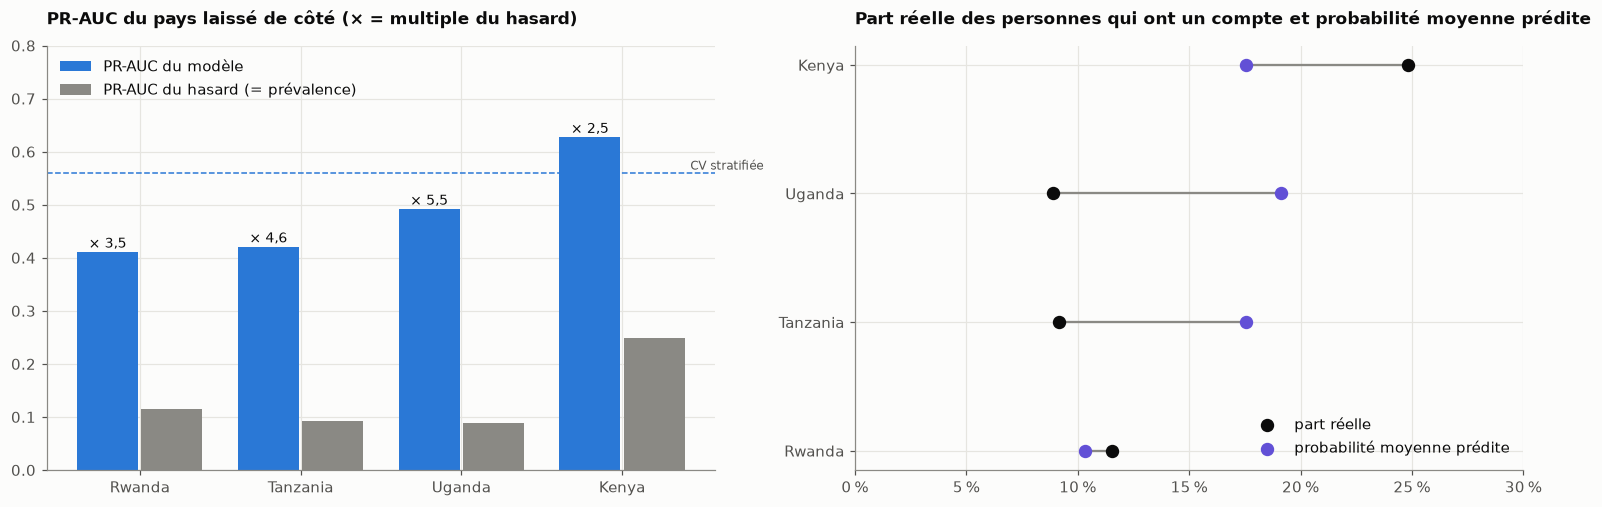

In [24]:
by_country = per_group_scores(logreg, X_train, y_train, groups, sgkf)
display(by_country.round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
names = by_country["groupe laissé de côté"]
x = np.arange(len(names))
ax1.bar(x - 0.2, by_country["pr_auc"], 0.38, color=viz.YES, label="PR-AUC du modèle")
ax1.bar(x + 0.2, by_country["prévalence"], 0.38, color=viz.INK_3, label="PR-AUC du hasard (= prévalence)")
for xi, (ap, lift) in enumerate(zip(by_country["pr_auc"], by_country["pr_auc / prévalence"])):
    ax1.annotate(f"× {viz.fr(f'{lift:.1f}')}", (xi - 0.2, ap), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax1.axhline(row_strat[("pr_auc", "val", "mean")], color=viz.YES, ls="--", lw=1)
ax1.annotate(" CV stratifiée", (len(names) - 0.6, row_strat[("pr_auc", "val", "mean")]), va="bottom", fontsize=8, color=viz.INK_2)
ax1.set_xticks(x, names)
ax1.set(title="PR-AUC du pays laissé de côté (× = multiple du hasard)", ylim=(0, 0.8))
ax1.legend(loc="upper left")
for xi, (real, pred) in enumerate(zip(by_country["prévalence"], by_country["proba moyenne prédite"])):
    ax2.plot([real, pred], [xi, xi], color=viz.INK_3, lw=1.5, zorder=1)
ax2.scatter(by_country["prévalence"], x, color=viz.INK, s=60, zorder=2, label="part réelle")
ax2.scatter(by_country["proba moyenne prédite"], x, color=viz.COMPOSITION[1], s=60, zorder=2, label="probabilité moyenne prédite")
ax2.set_yticks(x, names)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fmt_pct(v, 0)))
ax2.set(title="Part réelle des personnes qui ont un compte et probabilité moyenne prédite", xlim=(0, 0.3))
ax2.legend(loc="lower right")
viz.save(fig, "04_cv_par_pays")
plt.show()

**Réponse Q4.4.**

- **Vérification** : la boucle affiche bien un seul pays par pli de validation (Rwanda, Tanzanie, Ouganda, Kenya), absent de l'entraînement, avec sa propre prévalence (11,6 %, 9,2 %, 8,9 %, 24,8 %).
- **Comparaison** : la PR-AUC tombe de **0,561 ± 0,026** (CV stratifiée) à **0,487 ± 0,086** (CV par pays), la ROC-AUC de 0,849 à 0,822, et l'écart-type est multiplié par 3. Prédire un pays jamais vu est plus difficile, et la performance dépend beaucoup du pays. La CV stratifiée mesure la performance **dans les quatre pays connus** ; la CV par pays, la performance **dans un pays nouveau**.
- **Pourquoi la PR-AUC n'est pas comparable d'un pays à l'autre** : son niveau de hasard est la prévalence du pays. Le Kenya a la PR-AUC la plus haute (0,63), mais avec 24,8 % de positifs le hasard y fait déjà 0,25 : c'est seulement **2,5 fois** le hasard, contre **5,5 fois** en Ouganda (0,49 pour 8,9 %). Pour comparer, on divise par la prévalence, ou on regarde la ROC-AUC, insensible à la prévalence (0,80 à 0,84).
- **Le vrai problème est la calibration (graphique de droite).** Le pays laissé de côté est une modalité **inconnue** de l'encodeur (ses colonnes `country` valent 0) : le modèle perd l'effet pays et prédit un niveau moyen proche des pays d'entraînement. Il **surestime** la part des personnes qui ont un compte en Ouganda (19,1 % prédit contre 8,9 % réel) et en Tanzanie, et la **sous-estime** au Kenya (17,5 % contre 24,8 %). La banque centrale, qui additionne les probabilités, se tromperait d'un facteur 2.
- **Déployer au Sénégal (slide 28)** : le modèle n'a jamais vu ce pays. On peut attendre un **classement** correct (ROC-AUC autour de 0,8 en transfert), mais pas des **probabilités** justes : la prévalence sénégalaise est différente, et les questionnaires peuvent coder autrement les modalités (`job_type`, Q2.6). Il faut donc (1) collecter un échantillon étiqueté au Sénégal, (2) **mesurer** la performance sur cet échantillon avant tout usage, (3) **recalibrer** les probabilités et recalculer le seuil, et idéalement (4) réentraîner avec des données sénégalaises. La CV groupée par pays est l'estimation honnête de ce scénario ; la CV stratifiée serait trop optimiste.

### Suivi de Q2.6 · modalités rares et inconnues, pli par pli

Comme annoncé aux étapes 2 et 3, on vérifie ce que voit l'encodeur dans chaque pli d'entraînement : `fold_category_audit()` liste les modalités vues moins de 20 fois (regroupées) et celles absentes de l'entraînement (inconnues).

In [25]:
n_other = (X_train["education_level"] == "Other/Dont know/RTA").sum()
n_dk = (X_train["marital_status"] == "Dont know").sum()
print(f"Dans X_train : {n_other} « Other/Dont know/RTA » (sur 35) et {n_dk} « Dont know » (sur 8)")
print("\nCV stratifiée (5 plis)")
display(fold_category_audit(X_train, y_train, CV).drop(columns="laissé de côté").set_index("pli"))
print("CV groupée par pays (4 plis)")
fold_category_audit(X_train, y_train, sgkf, groups=groups).set_index("pli")

Dans X_train : 21 « Other/Dont know/RTA » (sur 35) et 8 « Dont know » (sur 8)

CV stratifiée (5 plis)


,variable,modalité,effectif entraînement,effectif validation,statut
pli,,,,,
0,marital_status,Dont know,4,4,rare : regroupée
0,education_level,Other/Dont know/RTA,17,4,rare : regroupée
1,marital_status,Dont know,7,1,rare : regroupée
1,education_level,Other/Dont know/RTA,15,6,rare : regroupée
2,marital_status,Dont know,6,2,rare : regroupée
2,education_level,Other/Dont know/RTA,17,4,rare : regroupée
3,marital_status,Dont know,7,1,rare : regroupée
3,education_level,Other/Dont know/RTA,18,3,rare : regroupée
4,marital_status,Dont know,8,0,rare : regroupée


CV groupée par pays (4 plis)


,laissé de côté,variable,modalité,effectif entraînement,effectif validation,statut
pli,,,,,,
0,Rwanda,country,Rwanda,0,6989,inconnue à l'entraînement
0,Rwanda,marital_status,Dont know,8,0,rare : regroupée
0,Rwanda,education_level,Other/Dont know/RTA,12,9,rare : regroupée
1,Tanzania,country,Tanzania,0,5343,inconnue à l'entraînement
1,Tanzania,marital_status,Dont know,8,0,rare : regroupée
1,Tanzania,education_level,Other/Dont know/RTA,19,2,rare : regroupée
2,Uganda,country,Uganda,0,1628,inconnue à l'entraînement
2,Uganda,marital_status,Dont know,8,0,rare : regroupée
2,Uganda,education_level,Other/Dont know/RTA,17,4,rare : regroupée


**Constats.**
- **CV stratifiée** : *Dont know* (4 à 8 occurrences) et *Other/Dont know/RTA* (15 à 18) sont **regroupées dans tous les plis**. Contrairement à notre estimation de l'étape 3 (≈ 22 par pli), *Other/Dont know/RTA* n'atteint jamais le seuil : le découpage train/test n'en a laissé que **21 sur 35** dans `X_train` (14 sont dans le test). Aucune modalité inconnue en validation : l'encodeur n'a jamais à improviser.
- **CV groupée par pays** : le **pays laissé de côté** est lui-même une modalité inconnue (d'où la perte de l'effet pays, Q4.4), et quand le **Kenya** est laissé de côté, *Dont know* est inconnue (ses 8 occurrences sont kenyanes). `handle_unknown="infrequent_if_exist"` les traite sans erreur. Aucune modalité de `job_type` n'est inconnue : le problème de cette variable est un décalage de sens, pas une absence.
- **À retenir pour l'étape 10** : le modèle final sera réajusté sur tout `X_train`, où *Other/Dont know/RTA* apparaît 21 fois (≥ 20) : elle y aura **sa propre colonne**, alors qu'elle était regroupée dans les plis. L'effet est minime (21 lignes), mais il faut le savoir.

### Q4.5 · Faut-il un `TimeSeriesSplit` ?

**Réponse Q4.5.** **Non.** `TimeSeriesSplit` (slide 27) sert quand les mêmes phénomènes sont observés **au fil du temps** et qu'on veut prédire le futur à partir du passé, sans jamais utiliser le futur pour prédire le passé. Ce n'est pas notre situation :

- **L'année est confondue avec le pays** (Q2.3) : chaque pays n'a été enquêté qu'une année. Un découpage par année (2016 → 2017 → 2018) reviendrait à prédire la Tanzanie à partir du Rwanda, puis le Kenya et l'Ouganda à partir des deux : c'est un découpage **par pays** déguisé, déjà étudié en Q4.4, et l'effet du temps resterait impossible à séparer de l'effet pays.
- **Ce n'est pas une série temporelle** : ce sont des enquêtes transversales, des personnes différentes interrogées une seule fois, sans ordre temporel à l'intérieur d'un pays et sans historique d'un même individu.
- **L'usage visé ne l'exige pas** : KaziPay et la banque centrale appliquent le modèle à la population actuelle des pays observés. Le risque de **dérive** existe (l'inclusion financière progresse vite avec le paiement mobile), mais ce jeu ne permet pas de la mesurer : il faudrait plusieurs vagues d'enquête dans un même pays. On le citera dans les limites, avec la recommandation de réévaluer le modèle sur une enquête récente.

### Synthèse de l'étape 4

| Élément | Choix | Où |
|---|---|---|
| Test sous scellé | 20 %, stratifié, `random_state=42`, ouvert à l'étape 10 seulement | `data.load_split()` |
| Validation croisée | `StratifiedKFold(5, shuffle=True, random_state=42)`, **un seul objet** pour tous les modèles | `evaluate.CV` |
| Métriques | PR-AUC (principale), ROC-AUC, Brier, log-loss, accuracy, précision, recall et coût par personne au seuil $t^*$ | `evaluate.SCORING` |
| Résumé | moyenne ± écart-type, entraînement et validation, temps | `evaluate.cv_summary()` |
| Transfert entre pays | `StratifiedGroupKFold(4)` par pays : PR-AUC 0,487 ± 0,086, probabilités mal calibrées | `evaluate.per_group_scores()` |
| Q2.6 | modalités rares regroupées dans tous les plis ; seules inconnues : le pays laissé de côté et *Dont know* (Kenya) | `features.fold_category_audit()` |

**Référence pour la suite** : le modèle de base obtient une PR-AUC de **0,561 ± 0,026** en CV stratifiée. Tout modèle plus complexe devra faire mieux de plus d'un écart-type.

### Point de contrôle

In [26]:
assert len(X_train) == 18_819 and len(X_test) == 4_705
assert abs(y_train.mean() - y_test.mean()) < 0.001
print(f"✓ X_train : {len(X_train):,} lignes ({y_train.mean():.2%} de positifs) · "
      f"X_test : {len(X_test):,} lignes ({y_test.mean():.2%}) — même prévalence ≈ 14,1 %")

✓ X_train : 18,819 lignes (14.08% de positifs) · X_test : 4,705 lignes (14.07%) — même prévalence ≈ 14,1 %
